In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = {
    'Student': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Hours_Studied': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
    'Marks': [35, 40, 43, 48, 52, 57, 61, 66, 70, 74]
}

df = pd.DataFrame(data)

print(df)

   Student  Hours_Studied  Marks
0        1              2     35
1        2              3     40
2        3              4     43
3        4              5     48
4        5              6     52
5        6              7     57
6        7              8     61
7        8              9     66
8        9             10     70
9       10             11     74


In [3]:
X = df[['Hours_Studied']]

y = df['Marks']

In [4]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model = LinearRegression()

In [5]:
scores = cross_val_score(
    model,
    X,
    y,
    cv=kfold,
    scoring='r2'
)

print("R2 Score for Each Fold:")

for i, score in enumerate(scores):
    print("Fold", i+1, ":", score)

print("\nAverage R2 Score:", np.mean(scores))

R2 Score for Each Fold:
Fold 1 : 0.9982200422777118
Fold 2 : 0.9997130394857667
Fold 3 : 0.9962144593186991
Fold 4 : 0.9982495408631773
Fold 5 : 0.999575470046567

Average R2 Score: 0.9983945103983844


In [6]:
mse_scores = -cross_val_score(
    model,
    X,
    y,
    cv=kfold,
    scoring='neg_mean_squared_error'
)

print("MSE for Each Fold:")

for i, score in enumerate(mse_scores):
    print("Fold", i+1, ":", score)

print("\nAverage MSE:", np.mean(mse_scores))

MSE for Each Fold:
Fold 1 : 0.4004904875148608
Fold 2 : 0.03472222222222242
Fold 3 : 0.500637755102038
Fold 4 : 0.2118055555555516
Fold 5 : 0.017936390532544064

Average MSE: 0.23311848218544337


In [7]:
rmse_scores = np.sqrt(mse_scores)

print("RMSE for Each Fold:")

for i, score in enumerate(rmse_scores):
    print("Fold", i+1, ":", score)

print("\nAverage RMSE:", np.mean(rmse_scores))

RMSE for Each Fold:
Fold 1 : 0.6328431776632034
Fold 2 : 0.186338998124983
Fold 3 : 0.7075575984342461
Fold 4 : 0.4602233757161316
Fold 5 : 0.13392681035753842

Average RMSE: 0.4241779920592205


In [8]:
y_pred = cross_val_predict(
    model,
    X,
    y,
    cv=kfold
)

print("Actual Marks:")
print(y.values)

print("\nPredicted Marks:")
print(y_pred)

Actual Marks:
[35 40 43 48 52 57 61 66 70 74]

Predicted Marks:
[34.91666667 39.11206897 43.82142857 48.07692308 52.5        56.75
 61.17307692 65.42857143 69.88793103 74.41666667]


In [9]:
results = pd.DataFrame({
    'Actual Marks': y.values,
    'Predicted Marks': y_pred
})

print(results)

   Actual Marks  Predicted Marks
0            35        34.916667
1            40        39.112069
2            43        43.821429
3            48        48.076923
4            52        52.500000
5            57        56.750000
6            61        61.173077
7            66        65.428571
8            70        69.887931
9            74        74.416667


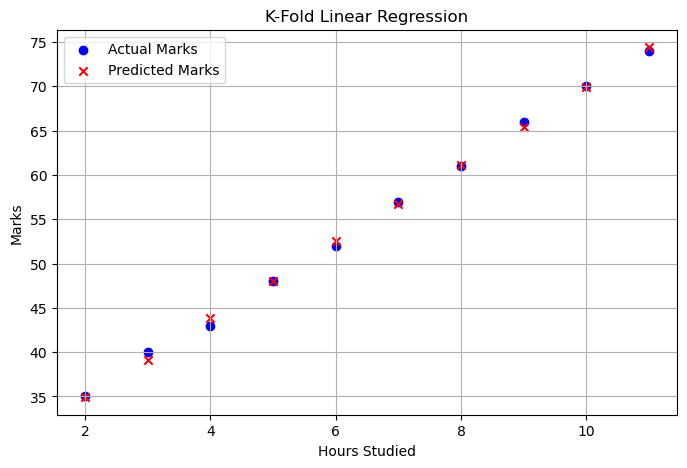

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X,
    y,
    color='blue',
    label='Actual Marks'
)

plt.scatter(
    X,
    y_pred,
    color='red',
    marker='x',
    label='Predicted Marks'
)

plt.xlabel('Hours Studied')
plt.ylabel('Marks')

plt.title('K-Fold Linear Regression')

plt.legend()
plt.grid(True)

plt.show()

In [11]:
final_model = LinearRegression()

final_model.fit(X, y)

print("Coefficient:", final_model.coef_)

print("Intercept:", final_model.intercept_)

Coefficient: [4.36363636]
Intercept: 26.23636363636364
